# Projeto 01 - Informações Nutricionais sobre Alimentos


- Pedro Domitti de Carvalho RA: 21005320
- Vinicus Augusto Papa Batista RA: 21004792
- Igor Roelli Silva RA: 21003696
- Gabriel Garcia RA: 21006394


In [625]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import scale

## Pré-processamento dos dados


In [626]:
df = pd.read_csv('../data/nutrition_food.csv')

df.head()

,ID,FoodGroup,ShortDescrip,Descrip,CommonName,MfgName,ScientificName,Energy_kcal,Protein_g,Fat_g,...,Folate_USRDA,Niacin_USRDA,Riboflavin_USRDA,Thiamin_USRDA,Calcium_USRDA,Copper_USRDA,Magnesium_USRDA,Phosphorus_USRDA,Selenium_USRDA,Zinc_USRDA
0,1001,Dairy and Egg Products,"BUTTER,WITH SALT","Butter, salted",NaN,NaN,NaN,717.0,0.85,81.11,...,0.0075,0.002625,0.026154,0.004167,0.020000,0.000000,0.004762,0.034286,0.018182,0.008182
1,1002,Dairy and Egg Products,"BUTTER,WHIPPED,WITH SALT","Butter, whipped, with salt",NaN,NaN,NaN,717.0,0.85,81.11,...,0.0075,0.002625,0.026154,0.004167,0.020000,0.000018,0.004762,0.032857,0.018182,0.004545
2,1003,Dairy and Egg Products,"BUTTER OIL,ANHYDROUS","Butter oil, anhydrous",NaN,NaN,NaN,876.0,0.28,99.48,...,0.0000,0.000188,0.003846,0.000833,0.003333,0.000001,0.000000,0.004286,0.000000,0.000909
3,1004,Dairy and Egg Products,"CHEESE,BLUE","Cheese, blue",NaN,NaN,NaN,353.0,21.40,28.74,...,0.0900,0.063500,0.293846,0.024167,0.440000,0.000044,0.054762,0.552857,0.263636,0.241818
4,1005,Dairy and Egg Products,"CHEESE,BRICK","Cheese, brick",NaN,NaN,NaN,371.0,23.24,29.68,...,0.0500,0.007375,0.270000,0.011667,0.561667,0.000027,0.057143,0.644286,0.263636,0.236364


In [627]:
# Drop colunas desnecessárias
df = df.drop(columns=['ID', 'CommonName', 'MfgName', 'ScientificName'])

# Drop valores nulos
df = df.dropna()

# Drop valores duplicados
df = df.drop_duplicates()

df.head()

,FoodGroup,ShortDescrip,Descrip,Energy_kcal,Protein_g,Fat_g,Carb_g,Sugar_g,Fiber_g,VitA_mcg,...,Folate_USRDA,Niacin_USRDA,Riboflavin_USRDA,Thiamin_USRDA,Calcium_USRDA,Copper_USRDA,Magnesium_USRDA,Phosphorus_USRDA,Selenium_USRDA,Zinc_USRDA
0,Dairy and Egg Products,"BUTTER,WITH SALT","Butter, salted",717.0,0.85,81.11,0.06,0.06,0.0,684.0,...,0.0075,0.002625,0.026154,0.004167,0.020000,0.000000,0.004762,0.034286,0.018182,0.008182
1,Dairy and Egg Products,"BUTTER,WHIPPED,WITH SALT","Butter, whipped, with salt",717.0,0.85,81.11,0.06,0.06,0.0,684.0,...,0.0075,0.002625,0.026154,0.004167,0.020000,0.000018,0.004762,0.032857,0.018182,0.004545
2,Dairy and Egg Products,"BUTTER OIL,ANHYDROUS","Butter oil, anhydrous",876.0,0.28,99.48,0.00,0.00,0.0,840.0,...,0.0000,0.000188,0.003846,0.000833,0.003333,0.000001,0.000000,0.004286,0.000000,0.000909
3,Dairy and Egg Products,"CHEESE,BLUE","Cheese, blue",353.0,21.40,28.74,2.34,0.50,0.0,198.0,...,0.0900,0.063500,0.293846,0.024167,0.440000,0.000044,0.054762,0.552857,0.263636,0.241818
4,Dairy and Egg Products,"CHEESE,BRICK","Cheese, brick",371.0,23.24,29.68,2.79,0.51,0.0,292.0,...,0.0500,0.007375,0.270000,0.011667,0.561667,0.000027,0.057143,0.644286,0.263636,0.236364


## Testando distribuição normal


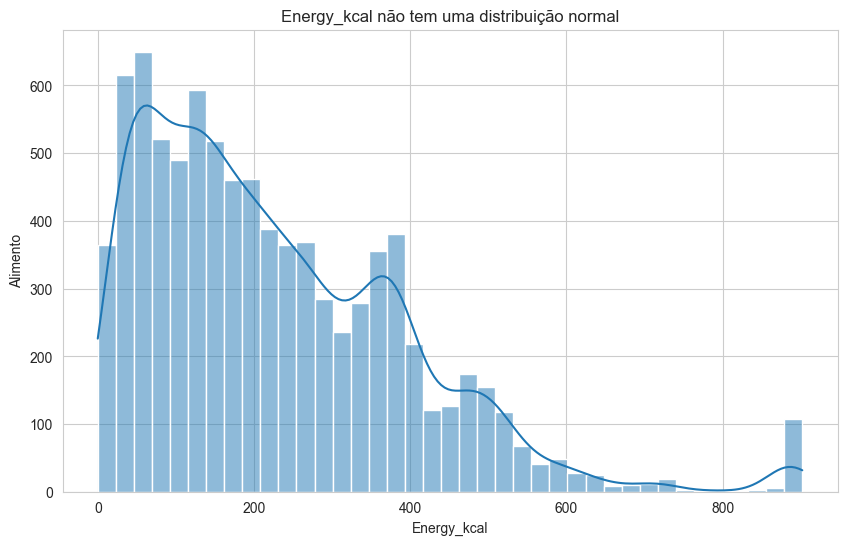

In [628]:
# Testando se "Energy_kcal" tem uma distribuição normal

def normal(data):
    # https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html
    # Função do scipy baseada no teste de D’Agostino e Pearson que combina distorção e curtose para testar a normalidade.
    _, p = stats.normaltest(data)

    # p < 0,05: Indica forte evidência contra a hipótese nula de normalidade, sugerindo que a variável pode não ter distribuição normal.
    if p < 0.05:
        dist_normal = f'{data.name} não tem uma distribuição normal'
    else:
        dist_normal = f'{data.name} tem uma distribuição normal'

    plt.figure(figsize=(10, 6))
    sns.histplot(data, kde=True)
    plt.title(dist_normal)
    plt.ylabel('Alimento')
    plt.xlabel(data.name)
    plt.show()

normal(df['Energy_kcal'])

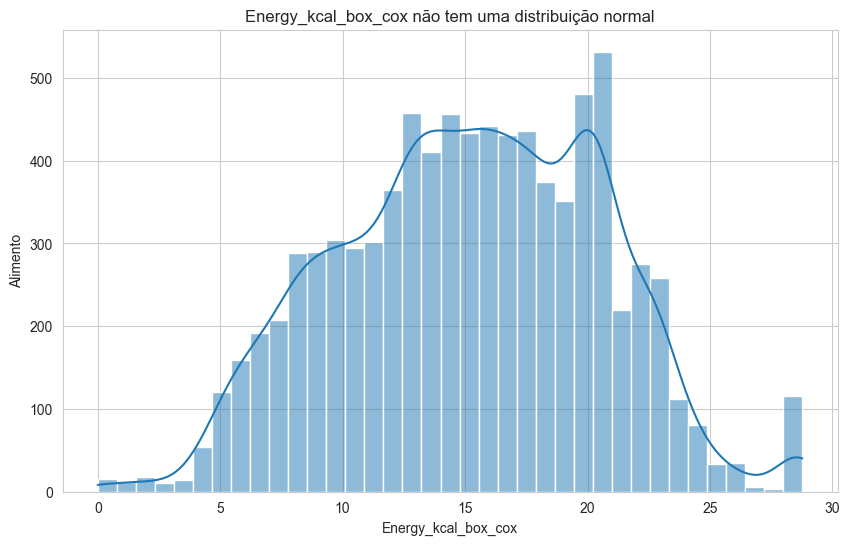

In [629]:
# Removendo valores negativos
df = df[df['Energy_kcal'] > 0]

# Aplicando a transformação de Box-Cox
df['Energy_kcal_box_cox'], _ = stats.boxcox(df['Energy_kcal'])

# Testando se agora "Energy_kcal_box_cox" tem uma distribuição normal
normal(df['Energy_kcal_box_cox'])

## Análise de Componentes Principais


In [630]:
# Encontrando quantos componentes principais são necessários para explicar 80% da variância

# Drop strings
df = df.select_dtypes(include=[np.number])

# Encontrando os componentes principais
pca = PCA()
cps = pca.fit_transform(scale(df.describe()))

# Componentes principais
resultado_pca = pd.DataFrame(cps, columns=[f'CP{i+1}' for i in range(cps.shape[1])])
print(resultado_pca.head())

# Autovalores
np.set_printoptions(suppress=True)
print(f'\nAutovalores:\n{pca.explained_variance_ratio_}')

# 80% da variância já é explicada com apenas o primeiro componente principal
total_var = pca.explained_variance_ratio_.cumsum()
n_comps = np.argmax(total_var >= 0.80) + 1
print(f'\nNúmero de componentes necessários para explicar 80% da variância: {n_comps}')

         CP1       CP2       CP3       CP4           CP5           CP6  \
0  15.955127 -0.296828 -0.000113 -0.000009  4.220579e-07  3.303933e-08   
1  -2.462223 -0.635619  0.022359  0.001430 -3.309403e-03  2.799617e-03   
2  -2.444340 -0.553970 -0.014826  0.027447  8.813747e-04 -3.279938e-04   
3  -2.493127 -0.675698 -0.059240 -0.009697 -2.458365e-03 -1.081425e-03   
4  -2.484655 -0.669823 -0.025986 -0.005468  2.116693e-03 -5.802369e-04   

            CP7           CP8  
0  2.109781e-08  2.622675e-16  
1  7.325834e-04  2.622675e-16  
2 -4.592368e-04  2.622675e-16  
3 -1.070753e-03  2.622675e-16  
4  2.295491e-03  2.622675e-16  

Autovalores:
[0.93730558 0.06266109 0.00002997 0.00000316 0.00000011 0.00000006
 0.00000003 0.        ]

Número de componentes necessários para explicar 80% da variância: 1


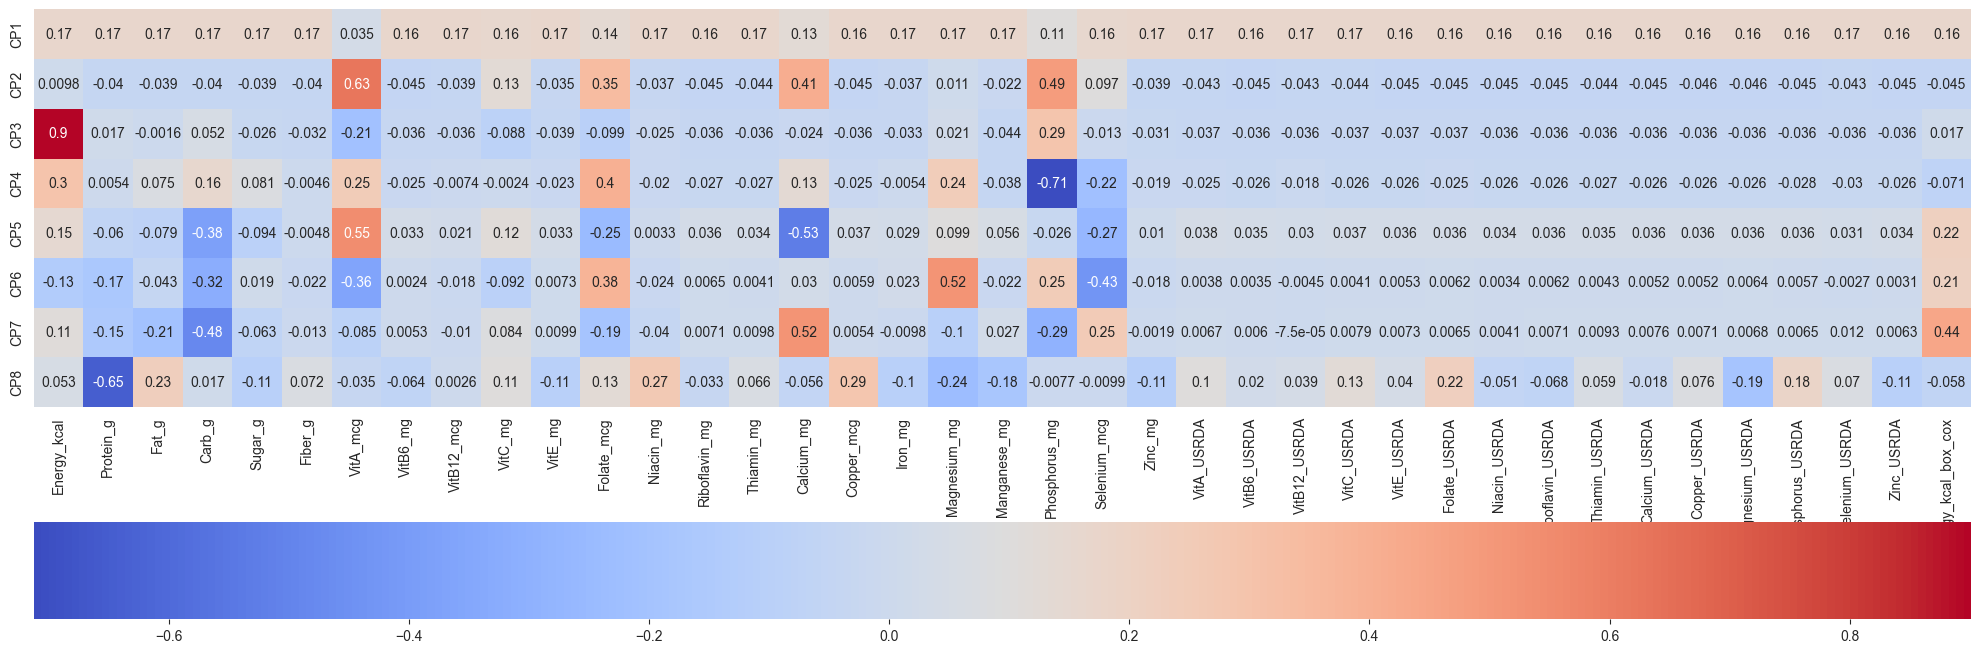

In [631]:
# Significado de cada componente principal
plt.figure(figsize=(25,10))

ax = sns.heatmap(pca.components_,
                 annot=True,
                 cmap='coolwarm',
                 yticklabels=[f'CP{i+1}' for i in range(len(pca.components_))],
                 xticklabels=df.describe().columns,
                 cbar_kws={'orientation': 'horizontal'})

ax.set_aspect('equal')

## Interpretação dos Componentes Principais

- Y1: Quantidade de Vitamina A, Cálcio e Fósforo
- Y2: Quantidade de Vitamina A, Folato (Vitamina B9), Cálcio e Fósforo
- Y3: Kcal e Fósforo (ATP Adenosina Tri-Fosfato - Energia) comparados à quantidade de Vitamina A
- Y4: Folato (Vitamina B9), Kcal, Vitaminas A e Magnésio comparados à quantidade de Fósforo
- Y5: Vitamina A comparada à quantidade de Cálcio
- Y6: Magnésio e Folato comparado à Vitamina A, Carboidratos e Selênio
- Y7: Cálcio comparado à Carboidratos e Fósforo
- Y8: Proteínas comparadas à Gorduras, Cobre e Niáce


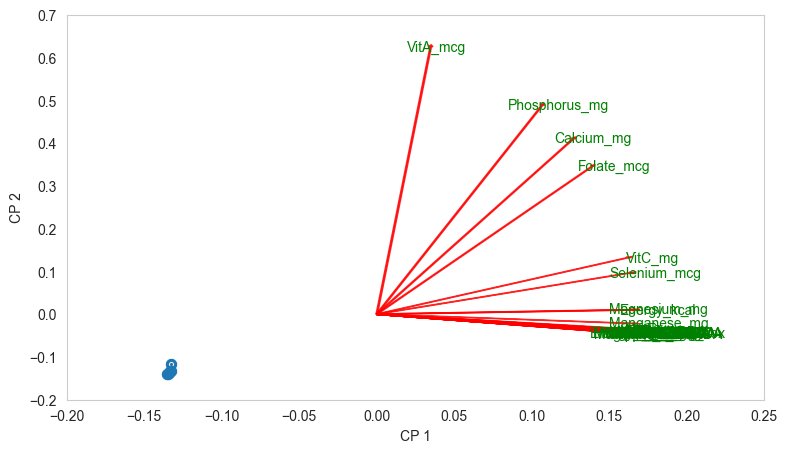

In [632]:
# Diagrama biplot para as duas primeiras componentes principais
fig, ax = plt.subplots(figsize=(9,5))

def myplot(score, coeff, labels=None):
    xs = score[:, 0]
    ys = score[:, 1]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())
    plt.scatter(xs * scalex, ys * scaley, s=5, linewidths = 6)

    for i in range(n):
        plt.arrow(0, 0, coeff[i, 0], coeff[i, 1], color = 'red', alpha = 0.8)

        plt.text(coeff[i, 0] * 1.1, coeff[i, 1] * 1, f'Var{i + 1}' if labels is None else labels[i], color = 'green', ha = 'center', va = 'center')

    plt.xlabel('CP 1')
    plt.ylabel('CP 2')
    ax.set(xlim=(-0.2, 0.25), ylim=(-0.2, 0.7))
    plt.grid()

myplot(resultado_pca.values[:, 0:2],np.transpose(pca.components_[0:2, :]),list(df.describe().columns))
plt.show()

# Como nenhuma variável é categórica, não podemos extrair informações relevantes sobre os alimentos